Cell 1:

In [18]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/SemEval2027'
print(os.listdir(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['dev (1).zip', 'dev_data', '__pycache__', 'data_loader.py', 'eda_output', 'eda.py']


Cell 2:

In [19]:
import zipfile

ZIP_NAME = 'dev (1).zip'
DATA_DIR = os.path.join(BASE, 'dev_data')

with zipfile.ZipFile(os.path.join(BASE, ZIP_NAME)) as z:
    z.extractall(DATA_DIR)

for root, dirs, files in os.walk(DATA_DIR):
    depth = root.replace(DATA_DIR, '').count(os.sep)
    print('  ' * depth + os.path.basename(root) + '/')
    for f in sorted(files)[:15]:
        size_kb = os.path.getsize(os.path.join(root, f)) / 1024
        print('  ' * (depth + 1) + f'{f}  ({size_kb:.1f} KB)')
    if len(files) > 15:
        print('  ' * (depth + 1) + f'... and {len(files) - 15} more files')

dev_data/
  SV/
    definitions.jsonl  (1.5 KB)
    subtask1.jsonl  (186.1 KB)
    subtask2.jsonl  (125.1 KB)
    usages.jsonl  (701.5 KB)
    usages_count.tsv  (0.4 KB)


Cell 3:

In [20]:
seen_ext = set()
for root, _, files in os.walk(DATA_DIR):
    for f in sorted(files):
        ext = os.path.splitext(f)[1]
        if ext in seen_ext:
            continue
        seen_ext.add(ext)
        path = os.path.join(root, f)
        print('=' * 80)
        print(path.replace(DATA_DIR, ''))
        print('=' * 80)
        with open(path, encoding='utf-8', errors='replace') as fh:
            for i, line in enumerate(fh):
                if i >= 5:
                    break
                print(line.rstrip()[:300])

/SV/definitions.jsonl
{"word": "kvinna", "definition": "Generell beteckning f\u00f6r kvinnok\u00f6net eller samtliga kvinnor i ett land / samfund (ofta i singularis best\u00e4md form, \"kvinnan\")"}
{"word": "sk\u00e4r", "definition": "Klar, blank, skir; ren, ljus och vacker; skinande vit, ljushyllt"}
{"word": "fr\u00f6ken", "definition": "Gift eller ogift yrkesut\u00f6vande kvinna, f\u00f6retr\u00e4desvis i skola, butik, postkontor, och bank"}
{"word": "dumpa", "definition": "L\u00e5ta n\u00e5got falla; l\u00e4gga eller s\u00e4nka ner"}
{"word": "exportera", "definition": "F\u00f6ra ut en produkt ur ett land (till ett annat land)"}
/SV/usages_count.tsv
word	1880-1883	1888-1891	1896-1899	1904-1907	1912-1915	2006-2007	2010-2011	2014-2015	2018-2019	2022-2023
dumpa	0	0	0	0	0	30	28	27	30	30
exportera	0	0	0	0	0	30	30	29	30	30
fru	29	26	23	18	28	30	30	30	30	30
fröken	28	23	30	23	23	4	9	23	7	4


Cell 4: show fields and example rows for every file

In [21]:
import pandas as pd
import json

SV_DIR = os.path.join(DATA_DIR, 'SV')
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

for fname in ['usages.jsonl', 'subtask1.jsonl', 'subtask2.jsonl', 'definitions.jsonl']:
    df = pd.read_json(os.path.join(SV_DIR, fname), lines=True)
    print('=' * 100)
    print(f'{fname}: {len(df)} rows, columns = {list(df.columns)}')
    print(df.dtypes.to_string())
    print(df.head(3).to_string())
    print()

counts = pd.read_csv(os.path.join(SV_DIR, 'usages_count.tsv'), sep='\t')
print('=' * 100)
print('usages_count.tsv')
print(counts.to_string())

usages.jsonl: 1983 rows, columns = ['word', 'sentence_id', 'text', 'pos', 'period_label', 'start', 'end', 'year']
word            object
sentence_id     object
text            object
pos             object
period_label    object
start            int64
end              int64
year             int64
     word     sentence_id                                                                                                                                                                                                          text pos period_label  start  end  year
0  kvinna  137d9286_62_69          nesliga lif medelst sjelfmord ; och ett stort antal olyckliga kvinnor , sorn sökt fly undan eländet , ha fallit i „mordeHglarnes4 händer , och deras ben vittra öfver allt i Utahs solbrända dalar .  NN    1880-1883     62   69  1883
1  kvinna  b382a5e9_92_98                                           — Jag sov ; jag väcktes av en kylande känsla , jag slog upp ögonen t.n vilklä<ld , beslöjaa kvinna s

Cell 5: load the data

In [22]:
import sys
sys.path.insert(0, BASE)            # lets Python find data_loader.py in  Drive folder

import importlib, data_loader
importlib.reload(data_loader)       # picks up the file again if we update it later
from data_loader import load_language, check_integrity, leave_one_word_out, ordered_periods

df = load_language(DATA_DIR, 'SV')
print(df.shape)
print(ordered_periods(df))
df[['word', 'target', 'period_label', 'period_index', 'year', 'senses', 'n_senses', 'target_sense']].head(10)

(1983, 20)
['1880-1883', '1888-1891', '1896-1899', '1904-1907', '1912-1915', '2006-2007', '2010-2011', '2014-2015', '2018-2019', '2022-2023']


,word,target,period_label,period_index,year,senses,n_senses,target_sense
0,dumpa,dumpade,2006-2007,5,2007,"[5, 7]",2,1
1,dumpa,dumpat,2006-2007,5,2007,[5],1,0
2,dumpa,dumpa,2006-2007,5,2007,[5],1,0
3,dumpa,dumpas,2006-2007,5,2007,[8],1,0
4,dumpa,dumpat,2006-2007,5,2007,"[5, 7]",2,1
5,dumpa,dumpar,2006-2007,5,2007,[5],1,0
6,dumpa,dumpat,2006-2007,5,2007,[5],1,0
7,dumpa,dumpade,2006-2007,5,2006,"[5, 7]",2,1
8,dumpa,dumpade,2006-2007,5,2006,"[5, 7]",2,1
9,dumpa,dumpa,2006-2007,5,2007,[5],1,0


Cell 6: run the integrity checks

In [23]:
report = check_integrity(df)

1983 usages, 10 words, 10 periods
  note: values stored as text and converted to numbers: {'start': 0, 'end': 0, 'year': 1983}
  note: offset repair: {'ok': 1969, 'kept_original': 9, 'repaired': 5}
  OK duplicate_keys: 0
  !! duplicate_texts: 10
  OK empty_text: 0
  OK offset_out_of_range: 0
  OK id_offset_mismatch: 0
  !! target_not_like_word: 14
  OK year_outside_period: 0
  OK missing_subtask1_label: 0
  OK period_mismatch_subtask1: 0
  OK missing_subtask2_label: 0
  !! duplicate_label_conflict: 4
  OK unreadable_numbers: 0


Cell 7: show any problem rows the checks found

In [24]:
for name, value in report.items():
    if not name.endswith('_rows') and value > 0:
        print(f'\n===== {name}: {value} rows =====')
        cols = ['word', 'sentence_id', 'target', 'period_label', 'year', 'text']
        print(report[name + '_rows'][cols].head(8).to_string())


===== duplicate_texts: 10 rows =====
           word       sentence_id       target period_label  year                                                                                                                                                            text
171   exportera      f05db5_11_22  exporterade    2006-2007  2007                                       Förra året exporterade Hägglunds för drygt 1,2 miljarder kronor , varav 671 miljoner räknas som krigsmateriel för strid .
172   exportera      f07056_11_22  exporterade    2006-2007  2007                                       Förra året exporterade Hägglunds för drygt 1,2 miljarder kronor , varav 671 miljoner räknas som krigsmateriel för strid .
717      fröken    32f03c86_44_50       fröken    2014-2015  2014                                             – Det var många som blev väldigt ledsna när fröken berättade att Khaled och Mohammed inte skulle få vara kvar här .
718      fröken    32f21e32_44_50       fröken    2014-201

Cell 8: find the values that were stored as text

In [25]:
import json
raw = [json.loads(l) for l in open(os.path.join(DATA_DIR, 'SV', 'usages.jsonl'), encoding='utf-8')]
for col in ['start', 'end', 'year']:
    bad = [(r['word'], r['sentence_id'], repr(r[col])) for r in raw if not isinstance(r[col], int)]
    print(f'{col}: {len(bad)} non-integer values')
    for b in bad[:5]:
        print('   ', b)

start: 0 non-integer values
end: 0 non-integer values
year: 1983 non-integer values
    ('kvinna', '137d9286_62_69', "'1883'")
    ('kvinna', 'b382a5e9_92_98', "'1914'")
    ('kvinna', '28ffffe7_42_50', "'1883'")
    ('kvinna', '3754909a_117_124', "'1913'")
    ('kvinna', '59ebb00_32_39', "'2007'")


Cell 9: confirm every flagged offset was handled correctly

In [26]:
flag = df[df['offset_status'] != 'ok']
pd.set_option('display.max_colwidth', 70)
print(flag['offset_status'].value_counts(), '\n')
print(flag[['word', 'period_label', 'target', 'target_fixed', 'offset_status']].to_string())

# Show each sentence with the original span in [[ ]] and the repaired span in << >>
for _, r in flag.iterrows():
    t = r['text']
    s, e, fs, fe = r['start'], r['end'], r['start_fixed'], r['end_fixed']
    marked = t[:s] + '[[' + t[s:e] + ']]' + t[e:]
    print(f"\n{r['word']} ({r['offset_status']}): {marked[max(0, s-60): e+60]}")
    if r['offset_status'] == 'repaired':
        print(f"   repaired -> ...{t[max(0, fs-30):fs]}<<{t[fs:fe]}>>{t[fe:fe+30]}...")

offset_status
kept_original    9
repaired         5
Name: count, dtype: int64 

      word period_label target target_fixed  offset_status
1792  skär    1896-1899   geme        skära       repaired
1796  skär    1896-1899  Hela         skärt       repaired
1797  skär    1896-1899    så          skär       repaired
1799  skär    1896-1899    hon         skär       repaired
1803  skär    1896-1899    trä         skär       repaired
1866  suga    2006-2007    sög          sög  kept_original
1871  suga    2006-2007   sögs         sögs  kept_original
1875  suga    2006-2007    sög          sög  kept_original
1877  suga    2006-2007    sög          sög  kept_original
1884  suga    2010-2011    sög          sög  kept_original
1934  suga    2018-2019   sögs         sögs  kept_original
1939  suga    2018-2019    sög          sög  kept_original
1964  suga    2022-2023    sög          sög  kept_original
1969  suga    2022-2023    sög          sög  kept_original

skär (repaired): h resedafärg , oc

Cell 10: the conflicting duplicates. Do the two copies get different senses?

In [27]:
dup = df[df.duplicated(['word', 'text'], keep=False)].sort_values(['word', 'text'])
dup_show = dup[['word', 'sentence_id', 'period_label', 'senses', 'target_sense']].copy()
dup_show['text_start'] = dup['text'].str[:60]
print(dup_show.to_string())

           word       sentence_id period_label senses  target_sense                                                    text_start
171   exportera      f05db5_11_22    2006-2007    [1]             1  Förra året exporterade Hägglunds för drygt 1,2 miljarder kro
172   exportera      f07056_11_22    2006-2007    [1]             1  Förra året exporterade Hägglunds för drygt 1,2 miljarder kro
717      fröken    32f03c86_44_50    2014-2015    [5]             0  – Det var många som blev väldigt ledsna när fröken berättade
718      fröken    32f21e32_44_50    2014-2015    [5]             0  – Det var många som blev väldigt ledsna när fröken berättade
812      förort  8f399853_111_121    2014-2015    [3]             1  Jan Edlings lösning är en integrationskommission och tydliga
819      förort  9a0cc80b_111_121    2014-2015    [3]             1  Jan Edlings lösning är en integrationskommission och tydliga
1887       suga    2728a3e1_73_77    2010-2011   [11]             0  BP tänker prova att s

Cell 11: usages per word and period. This is the main dataset table, and it also flags periods that are too small for Subtask 1b scoring.

In [28]:
periods = ordered_periods(df)
counts = (df.pivot_table(index='word', columns='period_label', values='sentence_id',
                         aggfunc='count', fill_value=0)
            .reindex(columns=periods, fill_value=0))
counts['TOTAL'] = counts.sum(axis=1)
counts.loc['TOTAL'] = counts.sum()
print(counts.to_string())

active = (counts.drop(index='TOTAL').drop(columns='TOTAL') > 0).sum(axis=1)
small = (counts.drop(index='TOTAL').drop(columns='TOTAL').replace(0, pd.NA) < 10).sum(axis=1)
print('\nperiods with any usage per word:\n', active.to_string())
print('\nperiods with 1-9 usages (excluded from 1b scoring):\n', small[small > 0].to_string())

period_label  1880-1883  1888-1891  1896-1899  1904-1907  1912-1915  2006-2007  2010-2011  2014-2015  2018-2019  2022-2023  TOTAL
word                                                                                                                             
dumpa                 0          0          0          0          0         30         28         27         30         30    145
exportera             0          0          0          0          0         30         30         29         30         30    149
fru                  29         26         23         18         28         30         30         30         30         30    274
fröken               28         23         30         23         23          4          9         23          7          4    174
förort                0          0          0          0          0         30         30         30         30         30    150
herre                28         24         27         27         28         29         30 

Cell 12: sentence length, historical vs modern

In [29]:
df['n_tokens'] = df['text'].str.split().str.len()
df['n_chars'] = df['text'].str.len()
from data_loader import period_start_year
df['era'] = df['period_label'].map(lambda p: 'historical (1880-1915)' if period_start_year(p) < 1950 else 'modern (2006-2023)')

length_by_era = df.groupby('era')[['n_tokens', 'n_chars']].describe().T
print(length_by_era.round(1).to_string())
print('\nshortest sentences:')
print(df.nsmallest(5, 'n_tokens')[['word', 'period_label', 'n_tokens', 'text']].to_string())
print('\nlongest sentences:')
print(df.nlargest(3, 'n_tokens')[['word', 'period_label', 'n_tokens']].to_string())

era             historical (1880-1915)  modern (2006-2023)
n_tokens count                   768.0              1215.0
         mean                     37.8                27.2
         std                      16.7                 7.0
         min                      16.0                16.0
         25%                      25.0                22.0
         50%                      33.0                26.0
         75%                      46.0                30.0
         max                     100.0                69.0
n_chars  count                   768.0              1215.0
         mean                    212.3               154.1
         std                      96.2                41.0
         min                      78.0                66.0
         25%                     142.0               126.0
         50%                     186.0               145.0
         75%                     262.2               173.5
         max                     573.0               351

Cell 13: per-word profile. Number of gold senses, multi-sense share, POS, and number of word forms.

In [30]:
per_word = df.groupby('word').agg(
    usages=('sentence_id', 'count'),
    n_gold_senses=('senses', lambda s: len({x for lst in s for x in lst})),
    multi_sense_share=('n_senses', lambda s: (s > 1).mean()),
    max_senses_one_usage=('n_senses', 'max'),
    target_sense_share=('target_sense', 'mean'),
    pos=('pos', lambda s: ', '.join(sorted(s.unique()))),
    forms=('target_fixed', lambda s: s.str.lower().nunique()),
)
print(per_word.round(3).to_string())
print('\nOverall: multi-sense usages = {:.1%}, target-sense usages = {:.1%}'.format(
    (df['n_senses'] > 1).mean(), df['target_sense'].mean()))

           usages  n_gold_senses  multi_sense_share  max_senses_one_usage  target_sense_share pos  forms
word                                                                                                    
dumpa         145              6              0.290                     2               0.310  VB      7
exportera     149              3              0.000                     1               0.946  VB      7
fru           274              5              0.288                     3               0.894  NN      6
fröken        174              4              0.040                     2               0.057  NN      4
förort        150              3              0.527                     3               0.493  NN      4
herre         283              8              0.148                     3               0.071  NN      8
kvinna        290              5              0.021                     2               0.228  NN      8
motiv         291              5              0.007    

Cell 14: imbalance. This is plan’s task “share of usages matching the target sense per period”

In [31]:
share = (df.pivot_table(index='word', columns='period_label', values='target_sense', aggfunc='mean')
           .reindex(columns=periods))
n_pos = (df.pivot_table(index='word', columns='period_label', values='target_sense', aggfunc='sum')
           .reindex(columns=periods))
print('Share of usages expressing the Subtask 2 target sense (blank = word absent in that period):')
print((share * 100).round(0).to_string(na_rep='-'))
print('\nNumber of target-sense usages:')
print(n_pos.to_string(na_rep='-'))
overall = df.groupby('period_label')['target_sense'].mean().reindex(periods)
print('\nAll words together, per period:')
print((overall * 100).round(1).to_string())
zero_cells = ((n_pos == 0)).sum().sum()
print(f'\nword-period cells with zero target-sense usages: {zero_cells} of {share.notna().sum().sum()}')

Share of usages expressing the Subtask 2 target sense (blank = word absent in that period):
period_label  1880-1883  1888-1891  1896-1899  1904-1907  1912-1915  2006-2007  2010-2011  2014-2015  2018-2019  2022-2023
word                                                                                                                      
dumpa                 -          -          -          -          -       47.0       43.0       22.0       17.0       27.0
exportera             -          -          -          -          -       90.0      100.0       93.0      100.0       90.0
fru                72.0       88.0       83.0       67.0       82.0      100.0       97.0      100.0       97.0       97.0
fröken              0.0        4.0        7.0        4.0       26.0        0.0        0.0        0.0        0.0        0.0
förort                -          -          -          -          -       40.0       37.0       43.0       77.0       50.0
herre              29.0       12.0       11.0  

# EDA Graphs

Cell 15: figures 1–7

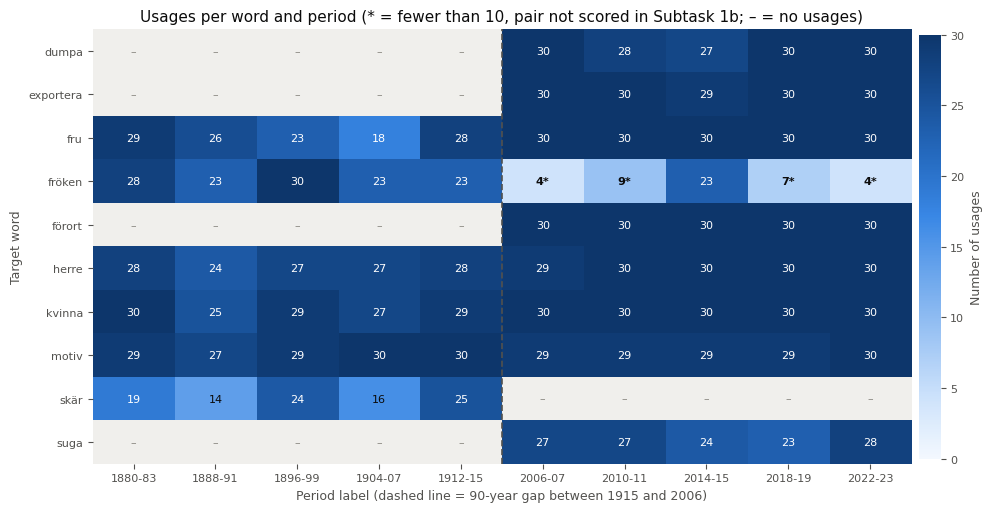

/content/drive/MyDrive/SemEval2027/eda.py:166: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


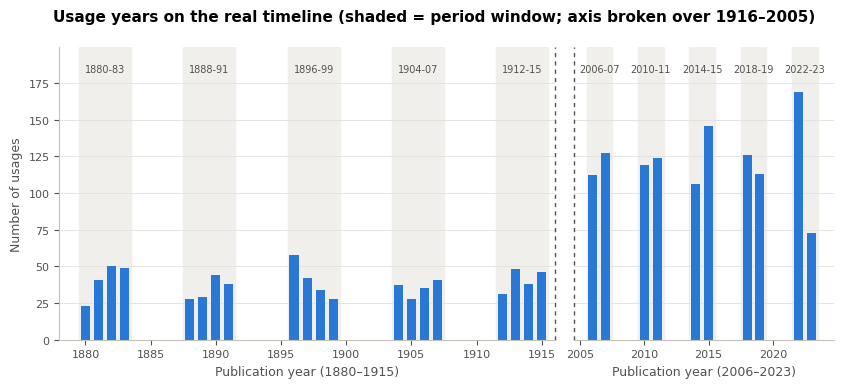

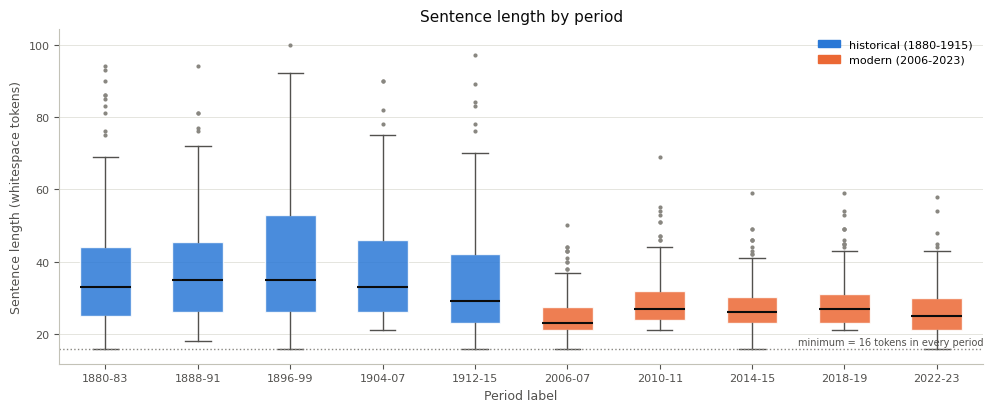

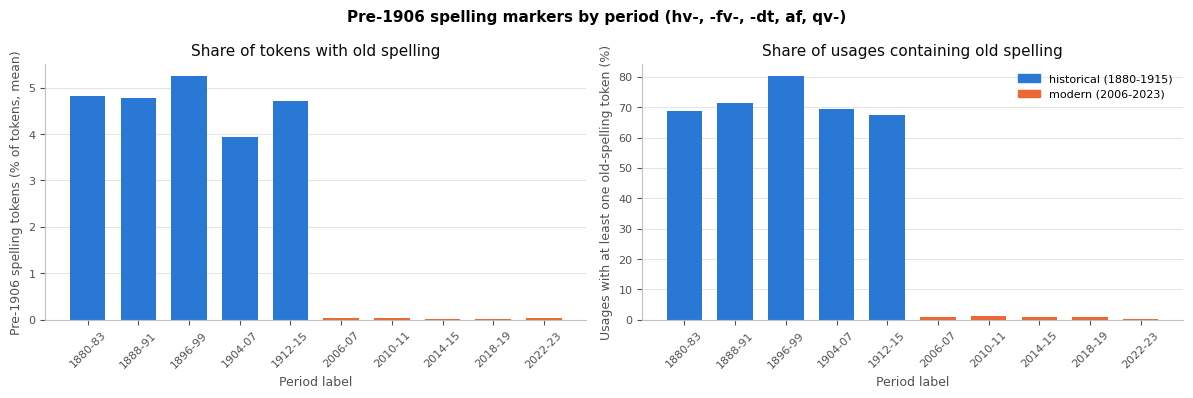

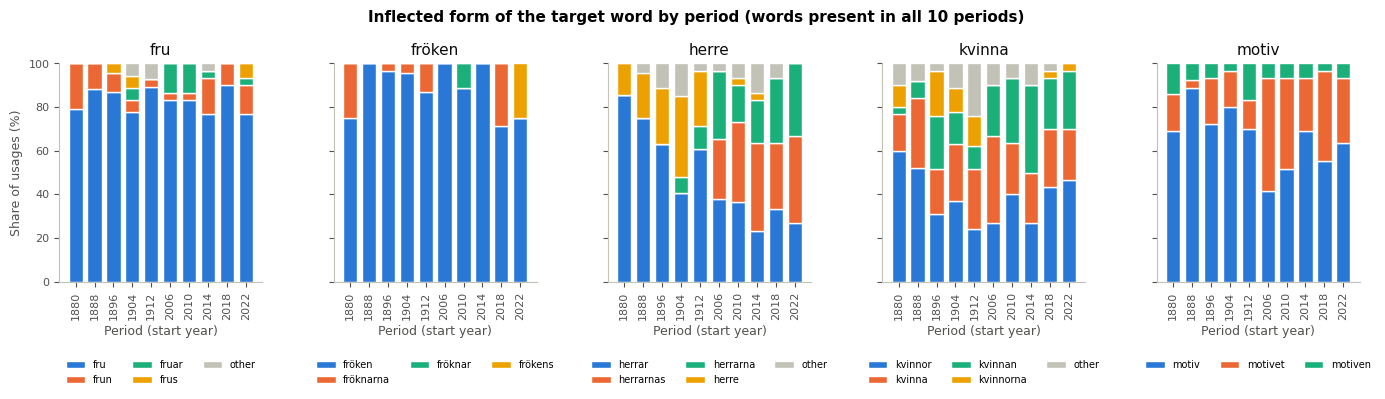

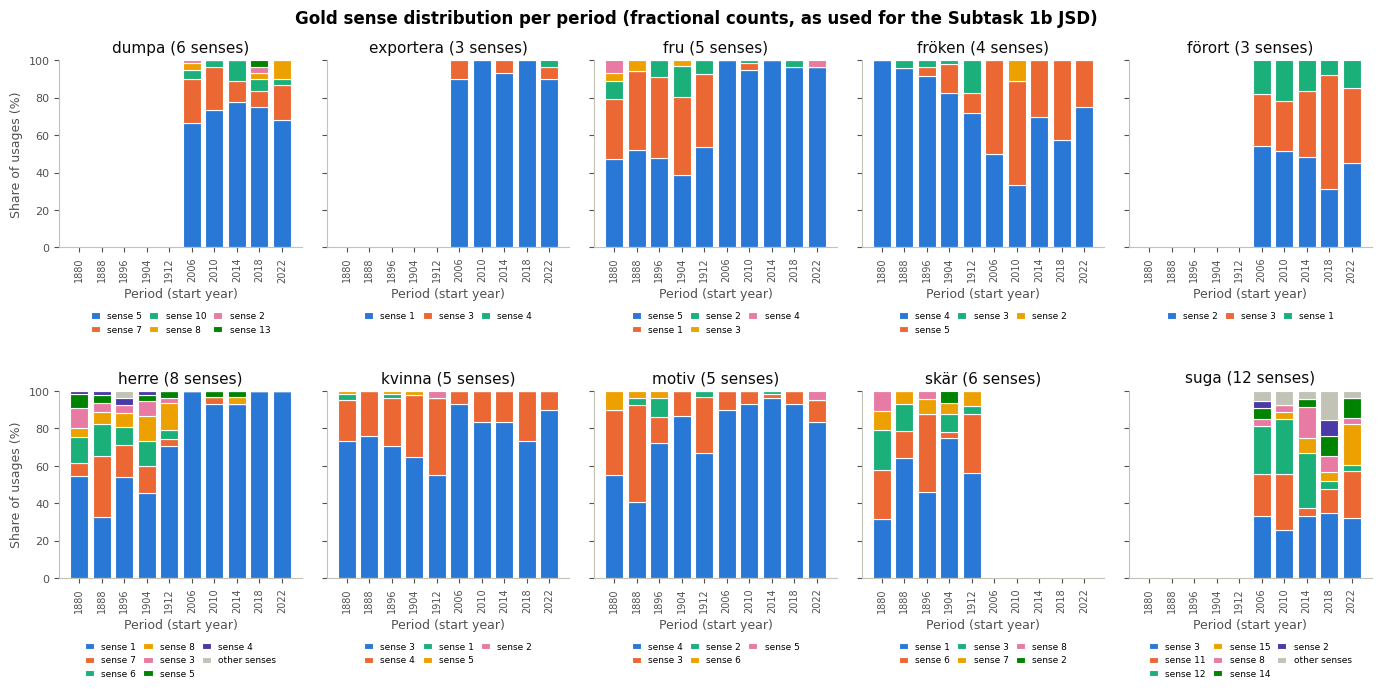

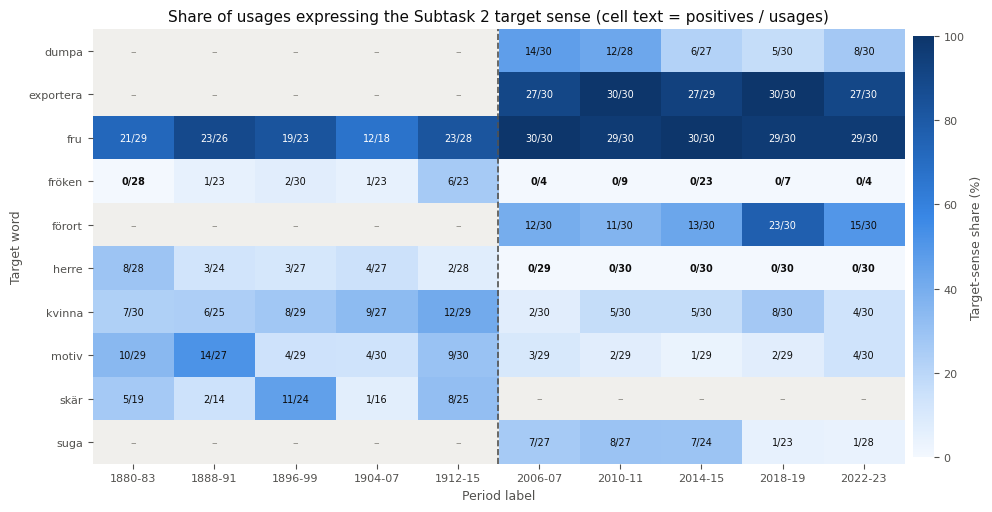

saved 7 figures to /content/drive/MyDrive/SemEval2027/eda_output/EDA_draft.pdf


In [35]:
import importlib, eda
importlib.reload(eda)
from eda import add_features, compute_embeddings, make_eda_pdf, eda_numbers, separation_scores

df = add_features(df)
OUT = os.path.join(BASE, 'eda_output')
os.makedirs(OUT, exist_ok=True)
make_eda_pdf(df, os.path.join(OUT, 'EDA_draft.pdf'), png_dir=os.path.join(OUT, 'png'))

Cell 16: embeddings for Figure 8. This takes about 1–2 minutes on a GPU. The result is saved to Drive.

(1983, 768)


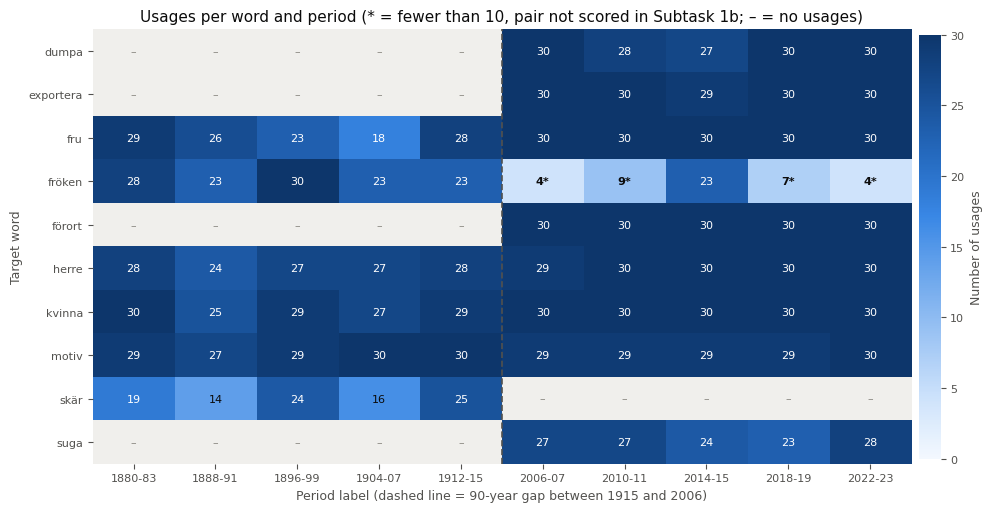

/content/drive/MyDrive/SemEval2027/eda.py:166: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


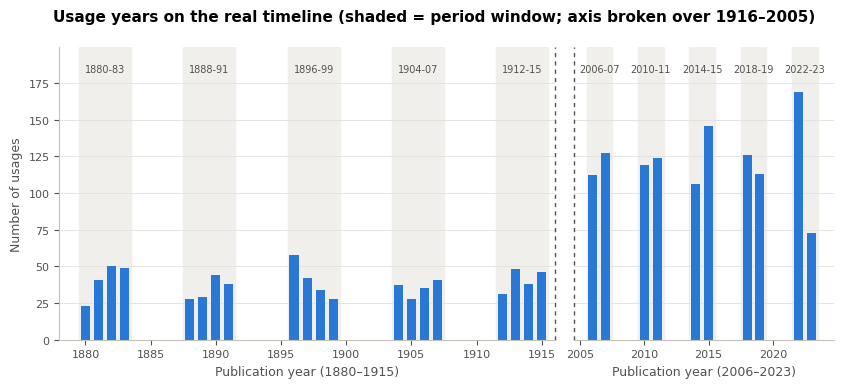

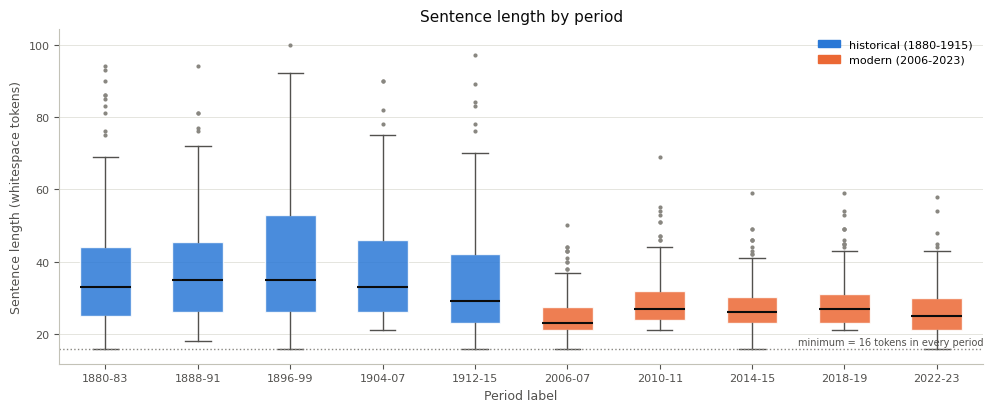

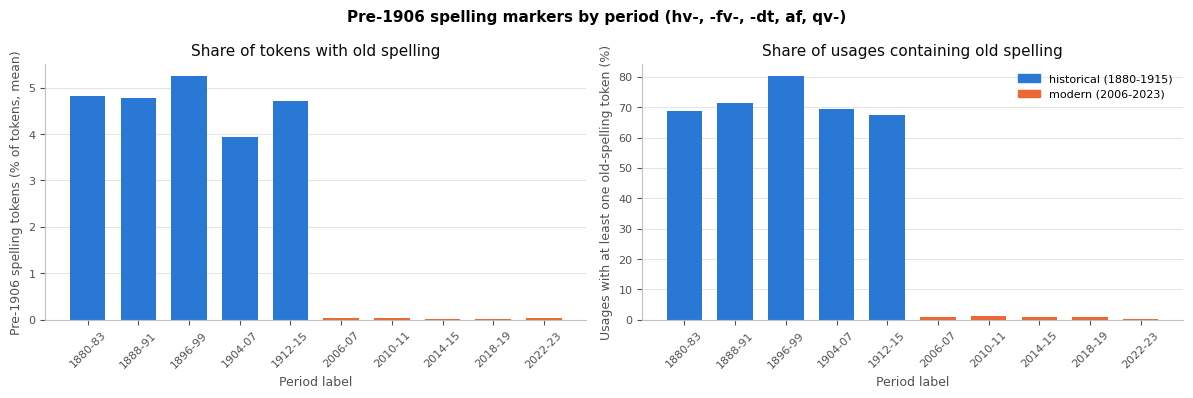

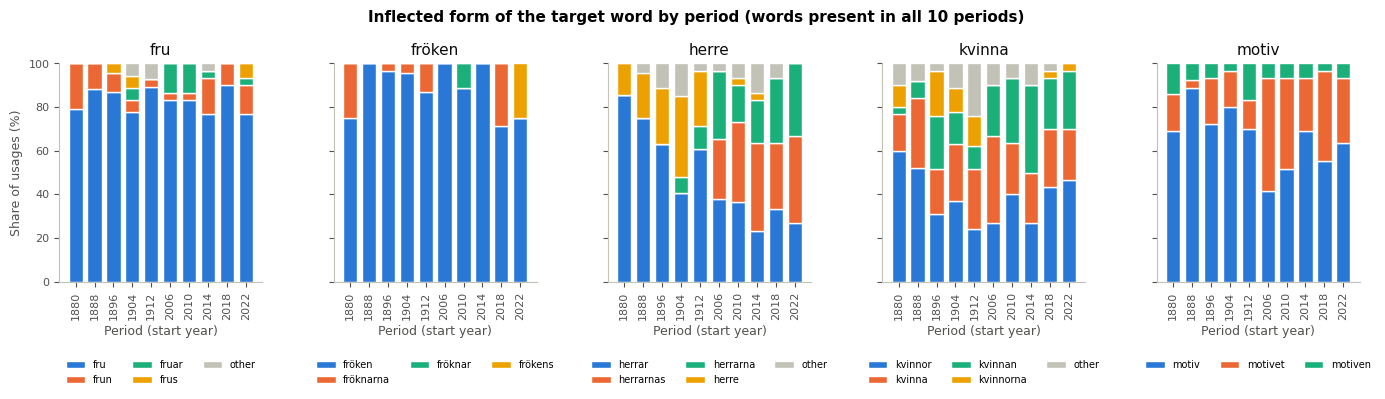

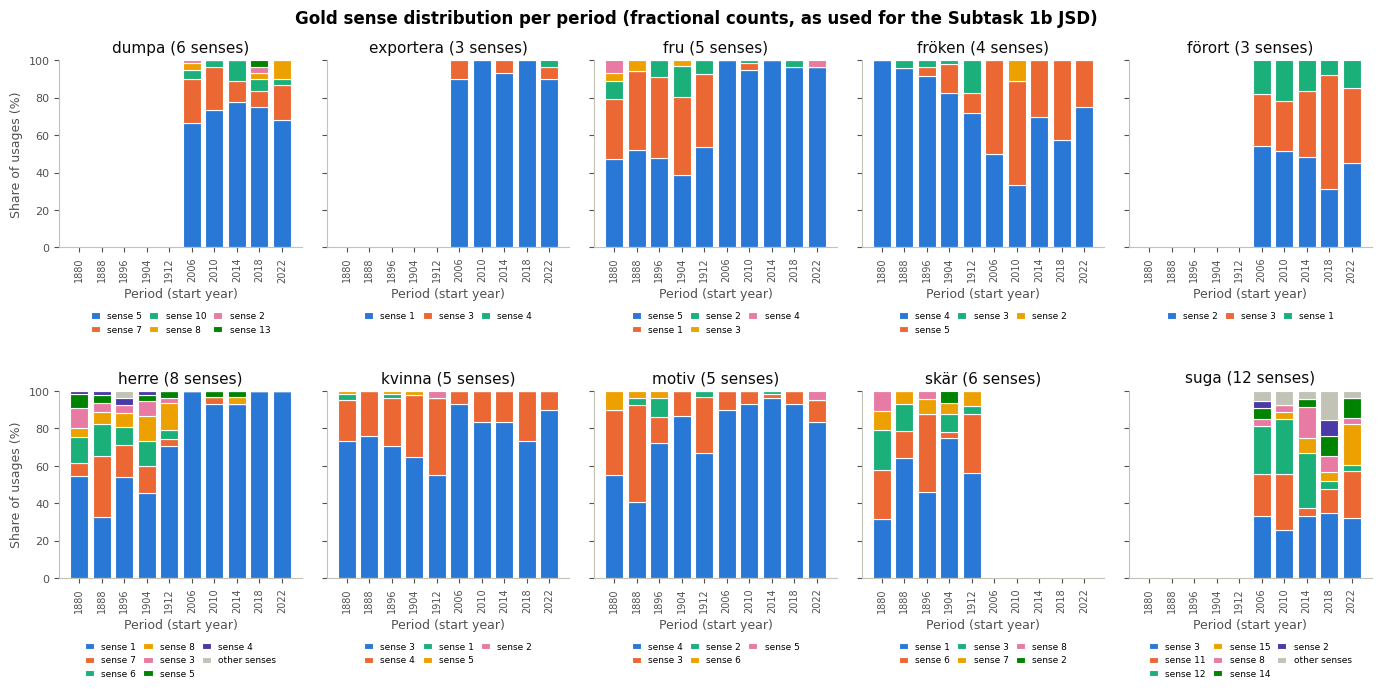

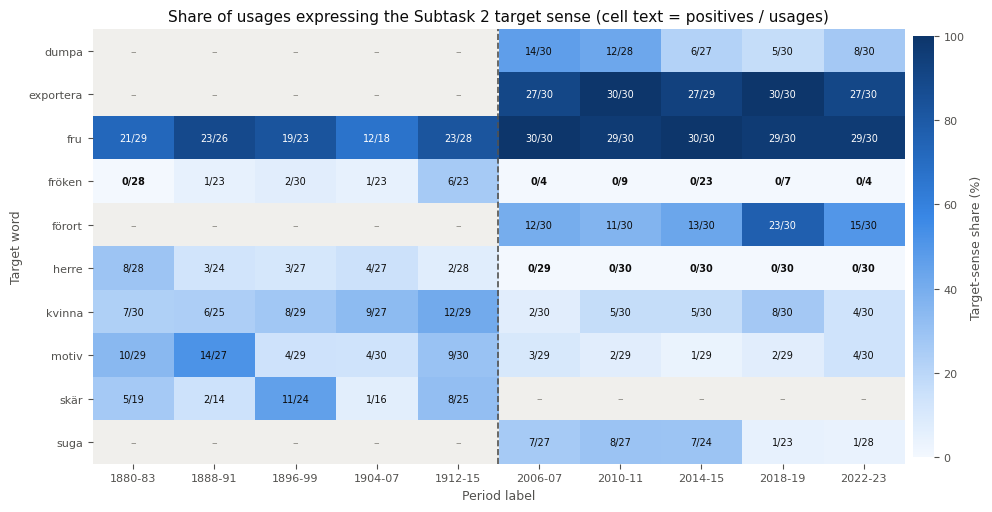

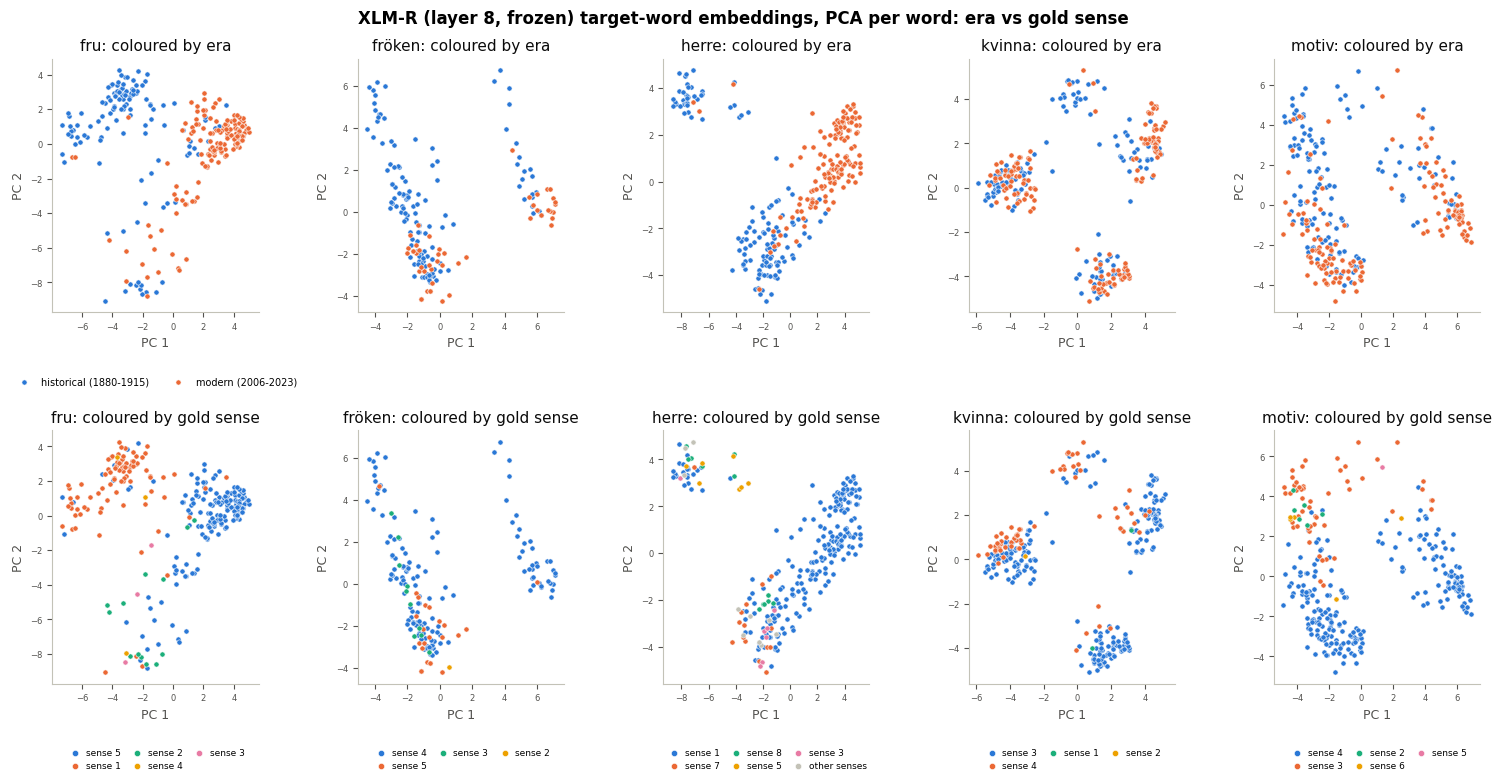

saved 8 figures to /content/drive/MyDrive/SemEval2027/eda_output/EDA.pdf


In [36]:
emb = compute_embeddings(df, cache_path=os.path.join(OUT, 'xlmr_layer8.npy'))
print(emb.shape)   # should be (1983, 768)
make_eda_pdf(df, os.path.join(OUT, 'EDA.pdf'), emb=emb, png_dir=os.path.join(OUT, 'png'))

Cell 17: the numbers behind the figures

In [34]:
eda_numbers(df, emb)

== Sentence length by era (tokens)
                         count  mean   std   min   25%   50%   75%    max
era                                                                      
historical (1880-1915)   768.0  37.8  16.7  16.0  25.0  33.0  46.0  100.0
modern (2006-2023)      1215.0  27.2   7.0  16.0  22.0  26.0  30.0   69.0

== Spelling / OCR rates by era (% of tokens, mean)
                        archaic_rate  ocr_noise_rate
era                                                 
historical (1880-1915)          4.72            0.19
modern (2006-2023)              0.03            0.39

== Usages with at least one archaic / OCR-like token, by era
                        any_arch  any_ocr
era                                      
historical (1880-1915)      71.5      4.6
modern (2006-2023)           0.8      8.1

== Distinct inflected forms per word, by era
era        historical (1880-1915)  modern (2006-2023)
word                                                 
dumpa                